## Assignment 11
Muyuan Ma

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_boston
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.svm import SVR
from sklearn.metrics import classification_report

In [2]:
# Load dataset
boston = load_boston()

C:\Users\mamuy\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:87: FutureWarning: Function load_boston is deprecated; `load_boston` is deprecated in 1.0 and will be removed in 1.2.

    The Boston housing prices dataset has an ethical problem. You can refer to
    the documentation of this function for further details.

    The scikit-learn maintainers therefore strongly discourage the use of this
    dataset unless the purpose of the code is to study and educate about
    ethical issues in data science and machine learning.

    In this special case, you can fetch the dataset from the original
    source::

        import pandas as pd
        import numpy as np


        data_url = "http://lib.stat.cmu.edu/datasets/boston"
        raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
        data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
        target = raw_df.values[1::2, 2]

    Alternative datasets include the California housing dataset (

In [3]:
# Description of the dataset
print(boston['DESCR'])

.. _boston_dataset:

Boston house prices dataset
---------------------------

**Data Set Characteristics:**  

    :Number of Instances: 506 

    :Number of Attributes: 13 numeric/categorical predictive. Median Value (attribute 14) is usually the target.

    :Attribute Information (in order):
        - CRIM     per capita crime rate by town
        - ZN       proportion of residential land zoned for lots over 25,000 sq.ft.
        - INDUS    proportion of non-retail business acres per town
        - CHAS     Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
        - NOX      nitric oxides concentration (parts per 10 million)
        - RM       average number of rooms per dwelling
        - AGE      proportion of owner-occupied units built prior to 1940
        - DIS      weighted distances to five Boston employment centres
        - RAD      index of accessibility to radial highways
        - TAX      full-value property-tax rate per $10,000
        - PTRATIO  pu

In [4]:
# Create DataFrame
boston_housing_df = pd.DataFrame(boston.data, columns=boston.feature_names)
boston_housing_df['MEDV'] = boston.target

### 1. Perform any necessary data preparation steps and EDA

In [5]:
# check the first 5 rows of the dataframe
print(boston_housing_df.head())

      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900  1.0  296.0   
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671  2.0  242.0   
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671  2.0  242.0   
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622  3.0  222.0   
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622  3.0  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2  


In [6]:
# check if there's any null data for each variable/column
print(boston_housing_df.isnull().sum())

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


In [7]:
# check the data type of each variable/column
print(boston_housing_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(14)
memory usage: 55.5 KB
None


In [8]:
# Descriptive statistics
print(boston_housing_df.describe())

             CRIM          ZN       INDUS        CHAS         NOX          RM  \
count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
mean     3.613524   11.363636   11.136779    0.069170    0.554695    6.284634   
std      8.601545   23.322453    6.860353    0.253994    0.115878    0.702617   
min      0.006320    0.000000    0.460000    0.000000    0.385000    3.561000   
25%      0.082045    0.000000    5.190000    0.000000    0.449000    5.885500   
50%      0.256510    0.000000    9.690000    0.000000    0.538000    6.208500   
75%      3.677083   12.500000   18.100000    0.000000    0.624000    6.623500   
max     88.976200  100.000000   27.740000    1.000000    0.871000    8.780000   

              AGE         DIS         RAD         TAX     PTRATIO           B  \
count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
mean    68.574901    3.795043    9.549407  408.237154   18.455534  356.674032   
std     28.148861    2.1057

The summary statistics for the Boston Housing dataset highlight some noteworthy aspects. For instance, there is a wide range in crime rates, with some areas having significantly higher rates (up to 88.98) compared to the mean of 3.61. The distribution of the proportion of residential land zoned for large lots (ZN) varies greatly, ranging from 0 to 100. Additionally, the dataset includes towns with diverse levels of industrialization, as indicated by the INDUS feature, which ranges from 0.46 to 27.74. These disparities across towns can have a substantial impact on housing prices.

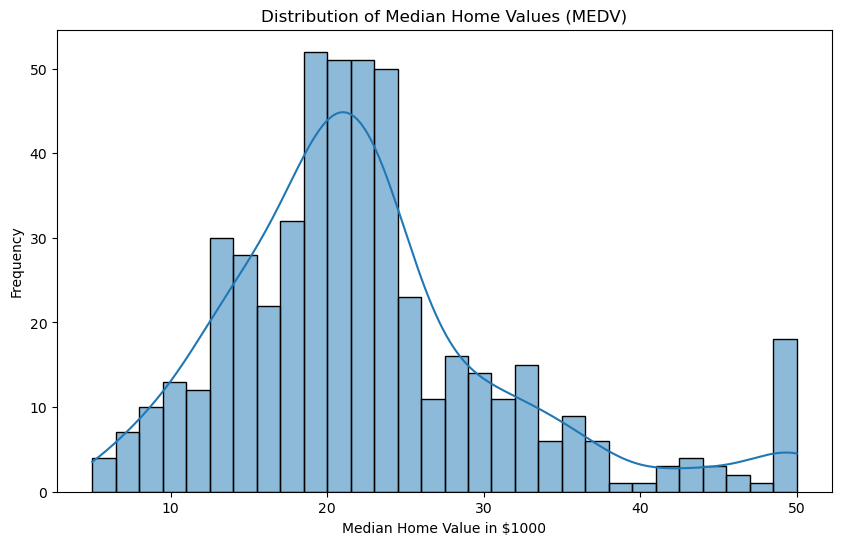

In [9]:
# Distribution of the target variable (MEDV)
plt.figure(figsize=(10, 6))
sns.histplot(boston_housing_df['MEDV'], bins=30, kde=True) # make a histogram
plt.title('Distribution of Median Home Values (MEDV)')
plt.xlabel('Median Home Value in $1000')
plt.ylabel('Frequency')
plt.show()

The histogram of the Boston Housing dataset shows a roughly normal distribution with a slight right-skew. The majority of median home values cluster around the mean (22.53) and median (21.2), while some outliers exist at the higher end, such as the maximum value of 50. The peak at 50 in the MEDV histogram indicates a significant number of towns with median home values capped appriximately at 50,000 US dollar. This could impact the predictive model's performance, especially for those homes with values close to 50,000 US dollar.

### 2. Normalize the numeric features and encode any categorical features.

#### Since there is no categorical feature to encode, which all of the features in the dataset are numerical in this case, I decide to proceed with scaling or normalization directly.

In [10]:
# Normalize the numeric features

# creates an instance of the StandardScaler class
scaler = StandardScaler()
# Fit the scaler on the entire dataset
scaler.fit(boston_housing_df[['CRIM', 'ZN', 'INDUS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']]) 
# Transform the entire dataset
boston_housing_df[['CRIM', 'ZN', 'INDUS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']] \
= scaler.transform(boston_housing_df[['CRIM', 'ZN', 'INDUS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']])

 ### 3. Partition the data into train/test sets.

In [11]:
# Partition the data into train/test sets
X = boston_housing_df.drop('MEDV', axis=1) # assign the dataframe without MEDV to X.
y = boston_housing_df['MEDV'] # assign MEDV column to y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### 4. Build the model that predicts the target variable, and use GridSearchCV to tune at least two hyperparameters, and perform cross validation.

I use GridSearchCV to tune two hyperparameters: C (the regularization parameter), gamma (the kernel coefficient), and kernel (transform the data into a higher-dimensional space). These hyperparameters control the tradeoff between achieving a low training error and a low testing error, and the shape of the decision boundary.

In [12]:
# normalize the numeric features in the training set
X_train = scaler.fit_transform(X_train)

In [13]:
# create the SVM model
svm = SVR()

# fit the model to the training data
svm.fit(X_train, y_train)

# scale the numeric features in the test data using the scaler object
X_test[['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']] \
= scaler.transform(X_test[['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']])

In [14]:
# predict using the trained model
y_pred = svm.predict(X_test)

# round the predicted target values to two decimal places using NumPy
y_pred_rounded = np.round(y_pred, 2)

# print the predicted target values
print('The predicted target values are: ', y_pred_rounded)

The predicted target values are:  [25.71 27.95 17.7  23.26 16.46 21.37 17.59 15.89 20.   19.43 21.85 19.42
 18.5  21.61 18.02 22.11 19.08 11.06 32.97 15.13 25.51 27.95 15.03 22.69
 15.59 15.26 21.65 13.56 21.56 18.84 19.43 24.12 18.81 18.82 14.69 17.86
 30.29 20.2  22.95 23.83 15.89 28.83 31.55 18.52 25.3  15.44 15.63 24.78
 18.31 29.23 20.78 31.92 17.14 24.44 35.42 22.31 16.26 28.33 24.17 16.21
 24.3  27.55 28.54 18.76 23.02 19.7  16.14 24.75 27.79 13.66 20.51 23.37
 10.81 20.58 22.54 14.42 19.53 31.48 14.13 15.47 20.74 12.02 21.42 11.87
 20.33 26.69 16.13 24.7  25.32 18.98 23.87 12.41 19.31 18.57 20.32 19.72
 19.54 15.25 13.   13.23 21.53 23.41 11.79 19.67 23.07 13.11 18.34 25.19
 21.52 23.69 12.   14.02 22.7  24.03 30.39 13.64 32.12 15.55 20.29 27.14
 16.68 24.98 20.2  21.46 24.22 21.74 24.54 29.33 20.26 35.83 17.01 25.32
 17.61 18.96 15.13 16.72 22.02 26.62 28.59 16.67 17.69 25.7  22.1  19.85
 15.13 22.63 20.66 14.65 15.74 33.89 14.23 15.84]


C:\Users\mamuy\anaconda3\lib\site-packages\sklearn\base.py:443: UserWarning: X has feature names, but SVR was fitted without feature names
  warnings.warn(


In [15]:
#evaluate the prediction accuracy
print('The accuracy of the model is: {:.2f}'.format(svm.score(X_test, y_test)))

The accuracy of the model is: 0.65


C:\Users\mamuy\anaconda3\lib\site-packages\sklearn\base.py:443: UserWarning: X has feature names, but SVR was fitted without feature names
  warnings.warn(


In [16]:
# calculate mean squared error
mse = mean_squared_error(y_test, y_pred)
print('Mean squared error: {:.2f}'.format(mse))

Mean squared error: 25.96


In [17]:
# calculate R2 score
r2 = r2_score(y_test, y_pred)
print('R2 score: {:.2f}'.format(r2))

R2 score: 0.65


The model has an accuracy score of 0.65, which is not meaningful. The mean squared error of 25.96 indicates that the model's predictions have an average squared error of approximately 5.10. The R2 score of 0.65 indicates that the model explains 65% of the variance in the target variable. Although these results may be acceptable, further analysis is needed to improve the model's accuracy and reduce the error.

In [18]:
# define the hyperparameter grid
params = {
    'C': [1, 10],
    'gamma': [1, 10]}

# initialize Grid Search with Cross Validation
svm_grid = GridSearchCV(estimator = svm, param_grid = params, cv=5, return_train_score=True)

# fit the model to the training data
print(svm_grid.fit(X_train, y_train))

GridSearchCV(cv=5, estimator=SVR(), param_grid={'C': [1, 10], 'gamma': [1, 10]},
             return_train_score=True)


### 5. Display: 1) the best model/parameters and 2) the best score that was obtained.

In [19]:
print("The best SVM model was found with the following hyperparameters: {}".format(svm_grid.best_params_))
print("The best score achieved was {:.2f}".format(svm_grid.best_score_))

The best SVM model was found with the following hyperparameters: {'C': 10, 'gamma': 1}
The best score achieved was 0.50


### 6. How do you feel about the model? Did it accurately predict the target? Evaluate the scores from GridSearchCV for the training set and the test set to diagnose any bias-variance problems.

In [20]:
#display the cv results for the train and test set
cv_results = pd.DataFrame(svm_grid.cv_results_)
cv_results = cv_results.sort_values('mean_test_score', ascending=False)
print(cv_results[['mean_train_score', 'std_train_score', 'mean_test_score', 'std_test_score']].head())

   mean_train_score  std_train_score  mean_test_score  std_test_score
2          0.902531         0.012920         0.501422        0.063215
0          0.277855         0.010541         0.151453        0.045755
3          0.809670         0.005470         0.033918        0.017221
1          0.131567         0.007322        -0.016514        0.025823


The model appears to be overfitting the training data, as indicated by the significantly higher mean training score of 0.9025 compared to the mean test score of 0.5014.

Based on the fact that the model appears to be overfitting the training data, I feel that the model may have a poor performance on new data. Thus, the model may not accurately predict the target variable on new, unseen data.